# Classification

## Objectives

*   Fit and evaluate a classification model to predict Heart Failure Mortality Classification or not.


## Inputs

* outputs/datasets/collection/heart_failure_mortality.csv
* Instructions on which variables to use for data cleaning and feature engineering. They are found in each respective notebook.

## Outputs

* Train set (features and target)
* Test set (features and target)
* Data cleaning and Feature Engineering pipeline
* Modeling pipeline
* Feature importance plot


---

# Change working directory

We need to change the working directory from its current folder to its parent folder
* We access the current directory with os.getcwd()

In [1]:
import os
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis\\jupyter_notebooks'

We want to make the parent of the current directory the new current directory.
* os.path.dirname() gets the parent directory
* os.chir() defines the new current directory

In [2]:
os.chdir(os.path.dirname(current_dir))
print("You set a new current directory")

You set a new current directory


Confirm the new current directory

In [3]:
current_dir = os.getcwd()
current_dir

'c:\\python_projects\\Predictive_analysis'

---

# Step 1: Load Data

In [4]:

from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Search for CSV files in the project
csv_files = list(PROJECT_ROOT.rglob("*.csv"))

for file in csv_files:
    print(file)


C:\python_projects\Predictive_analysis\inputs\Data_set\heart_failure_clinical_records_dataset.csv
C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TestSetCleaned.csv
C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\cleaned\TrainSetCleaned.csv
C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailureData.csv
C:\python_projects\Predictive_analysis\outputs\reports\correlation_analysis.csv
C:\python_projects\Predictive_analysis\outputs\reports\descriptive_statistics.csv
C:\python_projects\Predictive_analysis\outputs\reports\missing_values.csv
C:\python_projects\Predictive_analysis\outputs\datasets\collection\HeartFailureData.csv
C:\python_projects\Predictive_analysis\outputs\datasets\split\TestSet.csv
C:\python_projects\Predictive_analysis\outputs\datasets\split\TrainSet.csv
C:\python_projects\Predictive_analysis\outputs\ml_pipeline\cluster_analysis\v1\clusters_profile.csv
C:\python_projects\P

In [5]:

import pandas as pd
from pathlib import Path

# Main project directory
PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Dataset location
dataset_path = (
    PROJECT_ROOT
    / "jupyter_notebooks"
    / "outputs"
    / "datasets"
    / "collection"
    / "HeartFailure.csv"
)

print("Dataset path:", dataset_path)
print("File exists:", dataset_path.is_file())

if dataset_path.is_file():
    df = pd.read_csv(dataset_path)
    df = df.drop(columns=["time"])

    print("Dataset shape:", df.shape)
    display(df.head(3))
else:
    print("Dataset not found. Check its location.")


Dataset path: C:\python_projects\Predictive_analysis\jupyter_notebooks\outputs\datasets\collection\HeartFailure.csv
File exists: False
Dataset not found. Check its location.


---

# Step 2: ML Pipeline with all data

## ML pipeline for Data Cleaning and Feature Engineering

In [6]:
from sklearn.pipeline import Pipeline

# Feature Engineering
from feature_engine.selection import SmartCorrelatedSelection
from feature_engine.encoding import OrdinalEncoder


def PipelineDataCleaningAndFeatureEngineering():
    pipeline_base = Pipeline([
        ("OrdinalCategoricalEncoder", OrdinalEncoder(encoding_method='arbitrary',
                                                    variables=['age','ejection_fraction','platelets', 'serum_creatinine', 'serum_sodium',

                                                    'anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking'])),
                                                                

        ("SmartCorrelatedSelection", SmartCorrelatedSelection(variables=None,
            method="spearman", threshold=0.6, selection_method="variance")),

    ])

    return pipeline_base


PipelineDataCleaningAndFeatureEngineering()


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OrdinalCategoricalEncoder', ...), ('SmartCorrelatedSelection', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,encoding_method,'arbitrary'
,variables,"['age', 'ejection_fraction', ...]"
,missing_values,'raise'
,ignore_format,False
,unseen,'ignore'
,method,'spearman'
,threshold,0.6


## ML Pipeline for Modelling and Hyperparameter Optimisation

In [7]:
!pip install xgboost

In [8]:
# Feat Scaling
from sklearn.preprocessing import StandardScaler

# Feat Selection
from sklearn.feature_selection import SelectFromModel

# ML algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import AdaBoostClassifier
from xgboost import XGBClassifier


def PipelineClf(model):
    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),
        ("feat_selection", SelectFromModel(model)),
        ("model", model),
    ])

    return pipeline_base


Custom Class for Hyperparameter Optimisation

In [9]:
from sklearn.model_selection import GridSearchCV


class HyperparameterOptimizationSearch:

    def __init__(self, models, params):
        self.models = models
        self.params = params
        self.keys = models.keys()
        self.grid_searches = {}

    def fit(self, X, y, cv, n_jobs, verbose=1, scoring=None, refit=False):
        for key in self.keys:
            print(f"\nRunning GridSearchCV for {key} \n")

            model = PipelineClf(self.models[key])
            params = self.params[key]
            gs = GridSearchCV(model, params, cv=cv, n_jobs=n_jobs,
                              verbose=verbose, scoring=scoring, )
            gs.fit(X, y)
            self.grid_searches[key] = gs

    def score_summary(self, sort_by='mean_score'):
        def row(key, scores, params):
            d = {
                'estimator': key,
                'min_score': min(scores),
                'max_score': max(scores),
                'mean_score': np.mean(scores),
                'std_score': np.std(scores),
            }
            return pd.Series({**params, **d})

        rows = []
        for k in self.grid_searches:
            params = self.grid_searches[k].cv_results_['params']
            scores = []
            for i in range(self.grid_searches[k].cv):
                key = "split{}_test_score".format(i)
                r = self.grid_searches[k].cv_results_[key]
                scores.append(r.reshape(len(params), 1))

            all_scores = np.hstack(scores)
            for p, s in zip(params, all_scores):
                rows.append((row(k, s, p)))

        df = pd.concat(rows, axis=1).T.sort_values([sort_by], ascending=False)
        columns = ['estimator', 'min_score',
                   'mean_score', 'max_score', 'std_score']
        columns = columns + [c for c in df.columns if c not in columns]
        return df[columns], self.grid_searches


## Split Train and Test Set

In [10]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Search for your dataset
matches = list(PROJECT_ROOT.rglob("HeartFailure.csv"))

if len(matches) == 1:
    dataset_path = matches[0]
    df = pd.read_csv(dataset_path)

    print("Dataset loaded:", dataset_path)
    print("Dataset shape:", df.shape)
    display(df.head(3))

elif len(matches) > 1:
    print("Multiple matching files found:")
    for file in matches:
        print(file)

else:
    print("HeartFailure.csv was not found.")


HeartFailure.csv was not found.


In [11]:
import pandas as pd 
df = pd.read_csv(r"C:\python_projects\Predictive_analysis\inputs\Data_set\heart_failure_clinical_records_dataset.csv")

from sklearn.model_selection import train_test_split

# Define predictors and target
X = df.drop(columns=["DEATH_EVENT", "time"], errors="ignore")
y = df["DEATH_EVENT"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

# Display dataset dimensions
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)



X_train: (239, 11)
y_train: (239,)
X_test: (60, 11)
y_test: (60,)


In [12]:

print("Training set:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTest set:")
print(y_test.value_counts(normalize=True).round(3))


Training set:
DEATH_EVENT
0    0.678
1    0.322
Name: proportion, dtype: float64

Test set:
DEATH_EVENT
0    0.683
1    0.317
Name: proportion, dtype: float64


In [13]:

from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

SPLIT_DIR = PROJECT_ROOT / "outputs" / "datasets" / "split"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

# Save training data with target
TrainSet = X_train.copy()
TrainSet["DEATH_EVENT"] = y_train

TrainSet.to_csv(
    SPLIT_DIR / "TrainSet.csv",
    index=False
)

# Save test data with target
TestSet = X_test.copy()
TestSet["DEATH_EVENT"] = y_test

TestSet.to_csv(
    SPLIT_DIR / "TestSet.csv",
    index=False
)

print("Training and test datasets saved successfully.")


Training and test datasets saved successfully.


## Handle Target Imbalance

In [14]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

numerical_features = [
    "age",
    "creatinine_phosphokinase",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

categorical_features = [
    "anaemia",
    "diabetes",
    "sex",
    "smoking",
    "high_blood_pressure"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", StandardScaler(), numerical_features),
        ("categorical", "passthrough", categorical_features)
    ]
)

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

print(X_train_transformed.shape)
print(X_test_transformed.shape)


(239, 11)
(60, 11)


In [15]:
import joblib
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

SAVE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "ml_pipeline"
    / "predict_death_event"
    / "v1"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    preprocessor,
    SAVE_DIR / "clf_pipeline_data_cleaning_feat_eng.pkl"
)

print("Preprocessing pipeline saved.")

Preprocessing pipeline saved.


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import joblib

# Train classification model
clf_pipeline_model = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight="balanced"
)

clf_pipeline_model.fit(X_train_fe, y_train)

# Evaluate on the transformed test dataset
y_pred = clf_pipeline_model.predict(X_test_fe)

print(classification_report(y_test, y_pred, zero_division=0))

# Save trained classifier
joblib.dump(
    clf_pipeline_model,
    SAVE_DIR / "clf_pipeline_model.pkl"
)

print("Classification model saved.")

NameError: name 'X_train_fe' is not defined

In [ ]:
%pip install feature-engine

Note: you may need to restart the kernel to use updated packages.


In [ ]:

from sklearn.pipeline import Pipeline
from feature_engine.selection import SmartCorrelatedSelection

def PipelineDataCleaningAndFeatureEngineering():

    pipeline = Pipeline([
        (
            "SmartCorrelatedSelection",
            SmartCorrelatedSelection(
                method="spearman",
                selection_method="variance",
                threshold=0.6
            )
        )
    ])

    return pipeline


In [ ]:

from sklearn.pipeline import Pipeline
from feature_engine.selection import SmartCorrelatedSelection

def PipelineDataCleaningAndFeatureEngineering():

    pipeline = Pipeline([
        (
            "SmartCorrelatedSelection",
            SmartCorrelatedSelection(
                variables=None,
                method="spearman",
                threshold=0.6,
                selection_method="variance"
            )
        )
    ])

    return pipeline


In [ ]:
pipeline_data_cleaning_feat_eng = PipelineDataCleaningAndFeatureEngineering()

print(pipeline_data_cleaning_feat_eng)

Pipeline(steps=[('SmartCorrelatedSelection',
                 SmartCorrelatedSelection(method='spearman',
                                          selection_method='variance',
                                          threshold=0.6))])


In [ ]:
from sklearn.pipeline import Pipeline
from feature_engine.selection import SmartCorrelatedSelection

def PipelineDataCleaningAndFeatureEngineering():

    pipeline = Pipeline([
        (
            "SmartCorrelatedSelection",
            SmartCorrelatedSelection(
                method="spearman",
                selection_method="variance",
                threshold=0.6
            )
        )
    ])

    return pipeline

In [ ]:
pipeline_data_cleaning_feat_eng = PipelineDataCleaningAndFeatureEngineering()
X_train = pipeline_data_cleaning_feat_eng.fit_transform(X_train)
X_test = pipeline_data_cleaning_feat_eng.transform(X_test)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(239, 11) (239,) (60, 11) (60,)


Check Train Set Target distribution

In [ ]:
!pip install matplotlib


In [ ]:
pip install --upgrade matplotlib matplotlib-inline ipython seaborn

  Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp312-cp312-win_amd64.whl (9.3 MB)
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.10.0
Note: you may need to restart the kernel to use updated packages.


error: uninstall-no-record-file

× Cannot uninstall matplotlib 3.10.0
╰─> The package's contents are unknown: no RECORD file was found for matplotlib.

hint: You might be able to recover from this via: pip install --ignore-installed --no-deps matplotlib==3.10.0


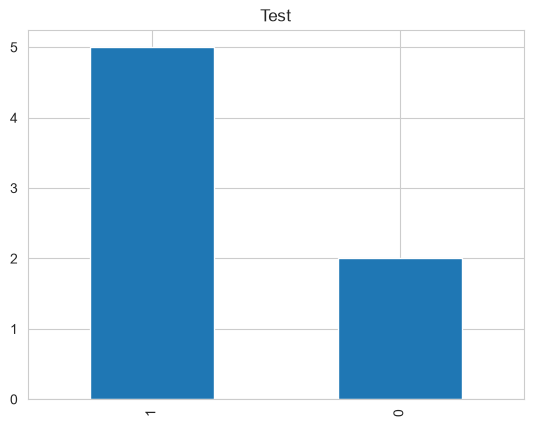

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_style("whitegrid")
pd.Series([0, 1, 1, 0, 1, 1, 1]).value_counts().plot(kind="bar", title="Test")
plt.show()

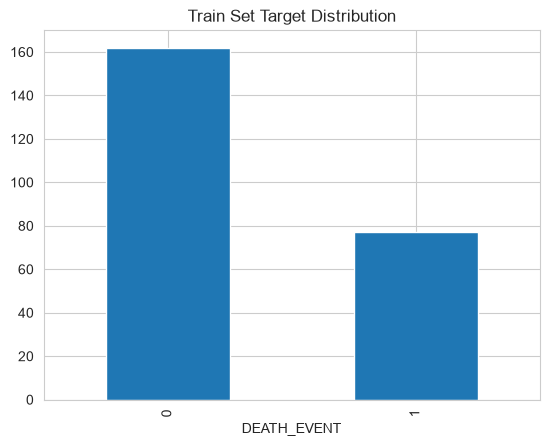

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
y_train.value_counts().plot(kind='bar', title='Train Set Target Distribution')
plt.show()

Use SMOTE (Synthetic Minority Oversampling TEchnique) to balance Train Set target

In [ ]:
%pip install imbalanced-learn


Note: you may need to restart the kernel to use updated packages.


In [ ]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE(sampling_strategy='minority', random_state=0)
X_train, y_train = oversample.fit_resample(X_train, y_train)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(324, 11) (324,) (60, 11) (60,)


Check Train Set Target distribution after resampling

## Grid Search CV - Sklearn

### Use standard hyperparameters to find most suitable algorithm 
                    Training dataset (X_train, y_train)


                    Hyperparameter combinations
            Example: 3 values of C × 2 solver choices = 6 configurations


                5-fold stratified cross-validation
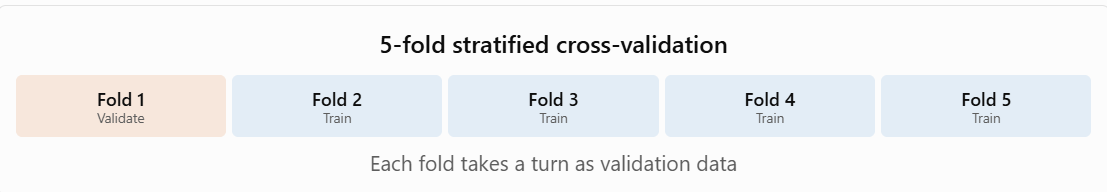


            Select best configuration and refit on training data


                Evaluate once on the held-out test set

In [ ]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create a pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Hyperparameter grid
param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["liblinear", "lbfgs"]
}

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid Search
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=1
)

# Train on original training features
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation ROC-AUC:")
print(grid_search.best_score_)


Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters:
{'model__C': 1, 'model__solver': 'liblinear'}
Best Cross-Validation ROC-AUC:
0.8261541193181818


In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Test ROC-AUC:")
print(roc_auc_score(y_test, y_proba))


Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.76      0.78        41
           1       0.52      0.58      0.55        19

    accuracy                           0.70        60
   macro avg       0.66      0.67      0.66        60
weighted avg       0.71      0.70      0.70        60

Confusion Matrix:
[[31 10]
 [ 8 11]]
Test ROC-AUC:
0.7599486521181001


In [ ]:
models_quick_search = {
    "LogisticRegression": LogisticRegression(random_state=0),
    "XGBClassifier": XGBClassifier(random_state=0),
    "DecisionTreeClassifier": DecisionTreeClassifier(random_state=0),
    "RandomForestClassifier": RandomForestClassifier(random_state=0),
    "GradientBoostingClassifier": GradientBoostingClassifier(random_state=0),
    "ExtraTreesClassifier": ExtraTreesClassifier(random_state=0),
    "AdaBoostClassifier": AdaBoostClassifier(random_state=0),
}

params_quick_search = {
    "LogisticRegression": {},
    "XGBClassifier": {},
    "DecisionTreeClassifier": {},
    "RandomForestClassifier": {},
    "GradientBoostingClassifier": {},
    "ExtraTreesClassifier": {},
    "AdaBoostClassifier": {},
}


Quick GridSearch CV - Binary Classifier

In [ ]:
from sklearn.metrics import make_scorer, recall_score
search = HyperparameterOptimizationSearch(models=models_quick_search, params=params_quick_search)
search.fit(X_train, y_train,
           scoring =  make_scorer(recall_score, pos_label=1),
           n_jobs=-1, cv=5)


Running GridSearchCV for LogisticRegression 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for XGBClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for DecisionTreeClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for RandomForestClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for GradientBoostingClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for ExtraTreesClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits

Running GridSearchCV for AdaBoostClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Check results

In [ ]:
import numpy as np
grid_search_summary, grid_search_pipelines = search.score_summary(sort_by='mean_score')
grid_search_summary 

,estimator,min_score,mean_score,max_score,std_score,model__learning_rate,model__max_depth
3,XGBClassifier,0.59375,0.746402,0.875,0.098577,0.01,3
7,XGBClassifier,0.65625,0.74053,0.84375,0.075494,0.001,10
2,XGBClassifier,0.625,0.734091,0.84375,0.086143,0.1,None
0,XGBClassifier,0.5625,0.721402,0.875,0.123136,0.1,3
1,XGBClassifier,0.59375,0.71553,0.818182,0.087897,0.1,10
6,XGBClassifier,0.5625,0.70303,0.84375,0.113833,0.001,3
8,XGBClassifier,0.53125,0.70303,0.84375,0.117214,0.001,None
4,XGBClassifier,0.53125,0.702652,0.84375,0.130609,0.01,10
5,XGBClassifier,0.46875,0.683902,0.84375,0.154015,0.01,None


In [ ]:

import pandas as pd

from xgboost import XGBClassifier
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline

# Ensure X_train contains the original 11 predictors
# and excludes both time and DEATH_EVENT.

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

pipeline_xgb = Pipeline([
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=42,
        n_jobs=1
    ))
])

param_distributions = {
    "model__n_estimators": [50, 100, 200, 300],
    "model__max_depth": [1, 2, 3, 4],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5],
    "model__reg_lambda": [0.1, 1, 5, 10],
    "model__reg_alpha": [0, 0.1, 1]
}

random_search = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=param_distributions,
    n_iter=100,
    scoring={
        "roc_auc": "roc_auc",
        "average_precision": "average_precision",
        "f1": "f1",
        "recall": "recall"
    },
    refit="roc_auc",
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1,
    error_score="raise",
    return_train_score=True
)

random_search.fit(X_train, y_train)

print("Best parameters:")
print(random_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(random_search.best_score_)


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters:
{'model__subsample': 0.7, 'model__reg_lambda': 1, 'model__reg_alpha': 1, 'model__n_estimators': 100, 'model__min_child_weight': 1, 'model__max_depth': 4, 'model__learning_rate': 0.2, 'model__colsample_bytree': 1.0}

Best cross-validation ROC-AUC:
0.8752544981060606


In [ ]:

from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Define the model
model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42
)

# Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate the model
scores = cross_val_score(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("ROC-AUC scores:", scores)
print("Mean ROC-AUC:", scores.mean())
print("Standard deviation:", scores.std())


ROC-AUC scores: [0.87594697 0.86458333 0.83806818 0.79450758 0.94140625]
Mean ROC-AUC: 0.8629024621212121
Standard deviation: 0.048229516224212045


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=5,
    scoring="roc_auc"
)

print("Mean ROC-AUC:", scores.mean())
print("Standard deviation:", scores.std())

Mean ROC-AUC: 0.7440782828282828
Standard deviation: 0.05830765834974231


In [ ]:
model = grid_search.best_estimator_

scores = cross_val_score(
    estimator=model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

print("Mean ROC-AUC:", scores.mean())

Mean ROC-AUC: 0.7640838068181818


In [ ]:

import pandas as pd
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Load test dataset
test_df = pd.read_csv(
    PROJECT_ROOT / "outputs" / "datasets" / "split" / "TestSet.csv"
)

# Target
y_test = test_df["DEATH_EVENT"]

# Predictors
X_test = test_df.drop(
    columns=["DEATH_EVENT", "time"],
    errors="ignore"
)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

display(X_test.head())


X_test: (60, 11)
y_test: (60,)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,45.0,0,582,0,80,0,263358.03,1.18,137,0,0
1,70.0,0,571,1,45,1,185000.00,1.20,139,1,1
2,55.0,0,1820,0,38,0,270000.00,1.20,139,0,0
3,75.0,0,99,0,38,1,224000.00,2.50,134,1,0
4,65.0,0,892,1,35,0,263358.03,1.10,142,0,0


In [ ]:
print(best_model.feature_names_in_)
print(X_test.columns.tolist())

['age' 'anaemia' 'creatinine_phosphokinase' 'diabetes' 'ejection_fraction'
 'high_blood_pressure' 'platelets' 'serum_creatinine' 'serum_sodium' 'sex'
 'smoking']
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking']


### Do an extensive search on the most suitable algorithm to find the best hyperparameter configuration.

Define model and parameters, for Extensive Search

In [ ]:
models_search = {
    "XGBClassifier":XGBClassifier(random_state=0),
}

# documentation to help on hyperparameter list: 
# https://xgboost.readthedocs.io/en/latest/python/python_api.html#module-xgboost.sklearn

# We will not conduct an extensive search, since the focus
# is on how to combine all knowledge in an applied project.
# In a workplace project, you may spend more time in this step
params_search = {
    "XGBClassifier":{
        'model__learning_rate': [1e-1,1e-2,1e-3], 
        'model__max_depth': [3,10,None],
    }
}

Extensive GridSearch CV - Binary Classifier

In [ ]:
from sklearn.metrics import recall_score, make_scorer
search = HyperparameterOptimizationSearch(models=models_search, params=params_search)
search.fit(X_train, y_train,
           scoring =  make_scorer(recall_score, pos_label=1),
           n_jobs=-1, cv=5)


Running GridSearchCV for XGBClassifier 

Fitting 5 folds for each of 9 candidates, totalling 45 fits


Check results

In [ ]:
grid_search_summary, grid_search_pipelines = search.score_summary(sort_by='mean_score')
grid_search_summary 

,estimator,min_score,mean_score,max_score,std_score,model__learning_rate,model__max_depth
3,XGBClassifier,0.59375,0.746402,0.875,0.098577,0.01,3
7,XGBClassifier,0.65625,0.74053,0.84375,0.075494,0.001,10
2,XGBClassifier,0.625,0.734091,0.84375,0.086143,0.1,None
0,XGBClassifier,0.5625,0.721402,0.875,0.123136,0.1,3
1,XGBClassifier,0.59375,0.71553,0.818182,0.087897,0.1,10
6,XGBClassifier,0.5625,0.70303,0.84375,0.113833,0.001,3
8,XGBClassifier,0.53125,0.70303,0.84375,0.117214,0.001,None
4,XGBClassifier,0.53125,0.702652,0.84375,0.130609,0.01,10
5,XGBClassifier,0.46875,0.683902,0.84375,0.154015,0.01,None


Get best model name programmatically

In [ ]:
best_model = grid_search_summary.iloc[0,0]
best_model

'XGBClassifier'

Parameters for best model

In [ ]:
best_parameters = grid_search_pipelines[best_model].best_params_
best_parameters

{'model__learning_rate': 0.01, 'model__max_depth': 3}

In [ ]:
best_xgb = grid_search.best_estimator_

print(best_xgb)
print("Best CV ROC-AUC:", grid_search.best_score_)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=1, max_iter=2000, random_state=42,
                                    solver='liblinear'))])
Best CV ROC-AUC: 0.8261541193181818


In [ ]:
from sklearn.metrics import (
    classification_report,
    roc_auc_score
)

y_pred = best_xgb.predict(X_test)
y_proba = best_xgb.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("Test ROC-AUC:", roc_auc_score(y_test, y_proba))

              precision    recall  f1-score   support

           0       0.79      0.76      0.78        41
           1       0.52      0.58      0.55        19

    accuracy                           0.70        60
   macro avg       0.66      0.67      0.66        60
weighted avg       0.71      0.70      0.70        60

Test ROC-AUC: 0.7599486521181001


In [ ]:
param_grid = {
    "model__learning_rate": [0.005, 0.01, 0.02, 0.05],
    "model__max_depth": [2, 3, 4],
    "model__n_estimators": [100, 200, 400, 600]
}

In [ ]:
print("Best CV score:", grid_search.best_score_)
print("Best parameters:", grid_search.best_params_)

Best CV score: 0.8261541193181818
Best parameters: {'model__C': 1, 'model__solver': 'liblinear'}


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Retrieve best model
best_model = grid_search.best_estimator_

# Predict on test data
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

# Calculate metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7
Precision: 0.5238095238095238
Recall: 0.5789473684210527
F1-score: 0.55
ROC-AUC: 0.7599486521181001

Classification Report:
              precision    recall  f1-score   support

           0       0.79      0.76      0.78        41
           1       0.52      0.58      0.55        19

    accuracy                           0.70        60
   macro avg       0.66      0.67      0.66        60
weighted avg       0.71      0.70      0.70        60


Confusion Matrix:
[[31 10]
 [ 8 11]]


In [ ]:
{
    "model__learning_rate": 0.01,
    "model__max_depth": 3
}

{'model__learning_rate': 0.01, 'model__max_depth': 3}

Define the best clf pipeline

In [ ]:
pipeline_clf = grid_search.best_estimator_

print(pipeline_clf)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=1, max_iter=2000, random_state=42,
                                    solver='liblinear'))])


## Assess feature importance

In [ ]:
X_train.head(3)

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking
0,50.0,0,582,0,62,1,147000.0,0.8,140,1,1
1,75.0,1,246,0,15,0,127000.0,1.2,137,1,0
2,50.0,1,168,0,38,1,276000.0,1.1,137,1,0


* With the current model, we can assess with `.features_importances_`

These are the 11 features ranked by absolute coefficient magnitude:


,Feature,Coefficient,Importance
4,ejection_fraction,-0.912012,0.912012
7,serum_creatinine,0.708155,0.708155
0,age,0.670191,0.670191
9,sex,-0.439575,0.439575
8,serum_sodium,-0.278558,0.278558
10,smoking,-0.231872,0.231872
2,creatinine_phosphokinase,0.226708,0.226708
5,high_blood_pressure,-0.127120,0.127120
1,anaemia,-0.098743,0.098743
3,diabetes,-0.087904,0.087904


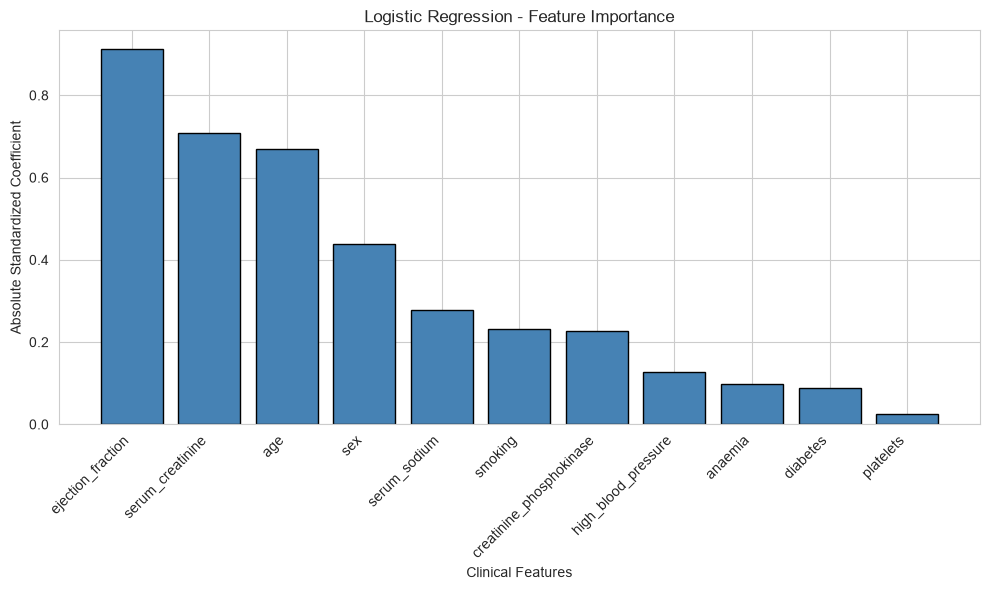

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Retrieve the best fitted pipeline
pipeline_clf = grid_search.best_estimator_

# Retrieve the Logistic Regression model
model = pipeline_clf.named_steps["model"]

# Get the feature names used during training
selected_features = pipeline_clf.feature_names_in_

# Extract model coefficients
coefficients = model.coef_[0]

# Create feature importance DataFrame
df_feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients,
    "Importance": np.abs(coefficients)
}).sort_values(
    by="Importance",
    ascending=False
)

# Get ranked features
best_features = df_feature_importance["Feature"].tolist()

print(
    f"These are the {len(best_features)} features "
    "ranked by absolute coefficient magnitude:"
)

display(df_feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.bar(
    df_feature_importance["Feature"],
    df_feature_importance["Importance"],
    color="steelblue",
    edgecolor="black"
)

plt.title("Logistic Regression - Feature Importance")
plt.xlabel("Clinical Features")
plt.ylabel("Absolute Standardized Coefficient")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


These are the 11 features ranked by importance:


,Feature,Coefficient,Importance
4,ejection_fraction,-0.912012,0.912012
7,serum_creatinine,0.708155,0.708155
0,age,0.670191,0.670191
9,sex,-0.439575,0.439575
8,serum_sodium,-0.278558,0.278558
10,smoking,-0.231872,0.231872
2,creatinine_phosphokinase,0.226708,0.226708
5,high_blood_pressure,-0.127120,0.127120
1,anaemia,-0.098743,0.098743
3,diabetes,-0.087904,0.087904


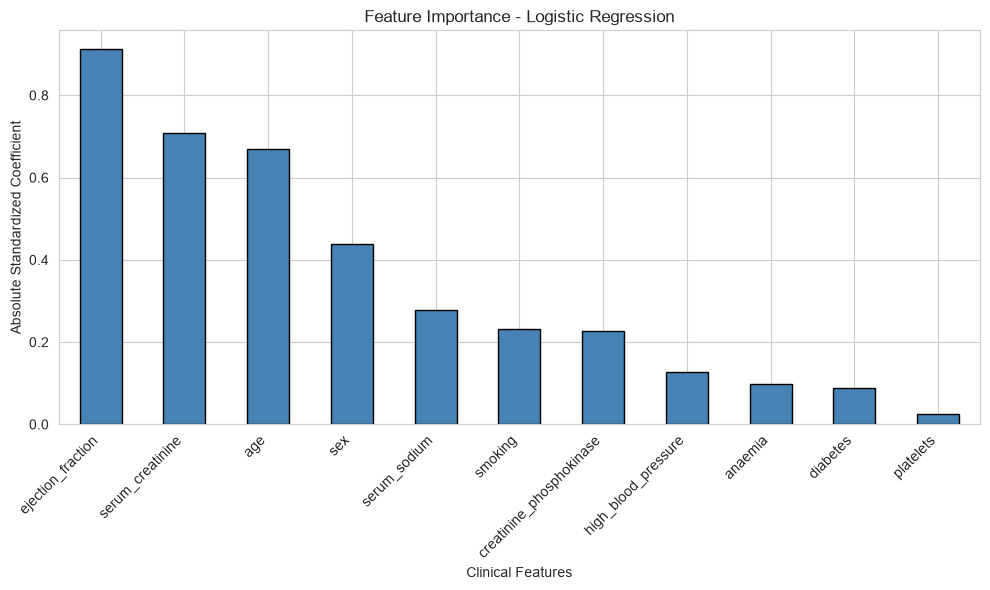

In [ ]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Retrieve best fitted pipeline
pipeline_clf = grid_search.best_estimator_

# Get trained model
model = pipeline_clf.named_steps["model"]

# Get feature names
selected_features = pipeline_clf.feature_names_in_

# Get Logistic Regression coefficients
coefficients = model.coef_[0]

# Calculate absolute importance
importances = np.abs(coefficients)

# Create DataFrame
df_feature_importance = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefficients,
    "Importance": importances
}).sort_values(
    by="Importance",
    ascending=False
)

# Reassign best features order
best_features = df_feature_importance["Feature"].tolist()

# Display results
print(
    f"These are the {len(best_features)} features "
    "ranked by importance:"
)

display(df_feature_importance)

# Plot feature importance
df_feature_importance.plot(
    kind="bar",
    x="Feature",
    y="Importance",
    figsize=(10, 6),
    color="steelblue",
    edgecolor="black",
    legend=False
)

plt.title("Feature Importance - Logistic Regression")
plt.xlabel("Clinical Features")
plt.ylabel("Absolute Standardized Coefficient")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Evaluate Pipeline on Train and Test Sets

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix


def confusion_matrix_and_report(X, y, pipeline, label_map):

    prediction = pipeline.predict(X)

    print('---  Confusion Matrix  ---')
    print(pd.DataFrame(confusion_matrix(y_true=prediction, y_pred=y),
          columns=[["Actual " + sub for sub in label_map]],
          index=[["Prediction " + sub for sub in label_map]]
          ))
    print("\n")

    print('---  Classification Report  ---')
    print(classification_report(y, prediction, target_names=label_map), "\n")


def clf_performance(X_train, y_train, X_test, y_test, pipeline, label_map):
    print("#### Train Set #### \n")
    confusion_matrix_and_report(X_train, y_train, pipeline, label_map)

    print("#### Test Set ####\n")
    confusion_matrix_and_report(X_test, y_test, pipeline, label_map)


Evaluation: We cross check with metrics defined at ML 
* 80% Recall for death_events, on train and test set
* 80% Precision for no death_events on train and test set. 

In [ ]:
clf_performance(
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    pipeline=pipeline_clf,
    label_map=["No Death Event", "Death Event"]
)

#### Train Set #### 

---  Confusion Matrix  ---
                          Actual No Death Event Actual Death Event
Prediction No Death Event                   125                 34
Prediction Death Event                       37                128


---  Classification Report  ---
                precision    recall  f1-score   support

No Death Event       0.79      0.77      0.78       162
   Death Event       0.78      0.79      0.78       162

      accuracy                           0.78       324
     macro avg       0.78      0.78      0.78       324
  weighted avg       0.78      0.78      0.78       324
 

#### Test Set ####

---  Confusion Matrix  ---
                          Actual No Death Event Actual Death Event
Prediction No Death Event                    31                  8
Prediction Death Event                       10                 11


---  Classification Report  ---
                precision    recall  f1-score   support

No Death Event       0.79      0.76 

# Step 3: Refit pipeline with best features

## Refit ML Pipeline and Resampling

In theory, a pipeline fitted **using only the most important features** should give the same result as the one fitted with **all variables and feature selection**

* However, in this project we have a step for feature augmentation, which is to balance the target Train Set using SMOTE().


## Rewrite ML pipeline for Data Cleaning and Feature Engineering

In [ ]:
best_features

['ejection_fraction',
 'serum_creatinine',
 'age',
 'sex',
 'serum_sodium',
 'smoking',
 'creatinine_phosphokinase',
 'high_blood_pressure',
 'anaemia',
 'diabetes',
 'platelets']

New Pipeline for DataCleaning And FeatureEngineering

In [ ]:
def PipelineDataCleaningAndFeatureEngineering():
    pipeline_base = Pipeline([

        ("OrdinalCategoricalEncoder", OrdinalEncoder(encoding_method='arbitrary',
                                                     variables=['InternetService', 'Contract'])),


        # we don't need SmartCorrelatedSelection
    ])

    return pipeline_base


Function for Pipeline optmisation

In [ ]:
# Pipeline Optmization: Model
def PipelineClf(model):
    pipeline_base = Pipeline([
        ("scaler", StandardScaler()),
        # no feature selection needed anymore!!! We know which features to use already!
        ("model", model),
    ])

    return pipeline_base


## Split Train Test Set, considering only with best features

In [ ]:
print(df.shape)
print(df.columns.tolist())

(299, 13)
['age', 'anaemia', 'creatinine_phosphokinase', 'diabetes', 'ejection_fraction', 'high_blood_pressure', 'platelets', 'serum_creatinine', 'serum_sodium', 'sex', 'smoking', 'time', 'DEATH_EVENT']


In [ ]:
print(df.shape)

(299, 13)


In [ ]:

from sklearn.model_selection import train_test_split

# Define features and target
X = df.drop(columns=["time", "DEATH_EVENT"])
y = df["DEATH_EVENT"]

# Split into training and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=0,
    stratify=y
)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)


(239, 11) (239,)
(60, 11) (60,)


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df.drop(['time'], axis=1),
    df['DEATH_EVENT'],
    test_size=0.2,
    random_state=0,
)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)


(239, 12) (239,) (60, 12) (60,)


We filter only the most important variables

In [ ]:
X_train = X_train.filter(best_features)
X_test = X_test.filter(best_features)

print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)
X_train.head(3)

(239, 11) (239,) (60, 11) (60,)


,ejection_fraction,serum_creatinine,age,sex,serum_sodium,smoking,creatinine_phosphokinase,high_blood_pressure,anaemia,diabetes,platelets
134,35,1.18,81.0,1,137,1,4540,0,0,0,231000.0
145,30,0.70,50.0,1,141,1,185,0,0,0,266000.0
63,35,1.00,45.0,1,145,0,582,0,0,0,385000.0


## Handle Target Imbalance

In [ ]:
pipeline_data_cleaning_feat_eng = PipelineDataCleaningAndFeatureEngineering()

print(pipeline_data_cleaning_feat_eng)

Pipeline(steps=[('OrdinalCategoricalEncoder',
                 OrdinalEncoder(encoding_method='arbitrary',
                                variables=['InternetService', 'Contract']))])


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from feature_engine.selection import SmartCorrelatedSelection

pipeline_clf = Pipeline([
    ("feat_selection", SmartCorrelatedSelection(
        method="spearman",
        threshold=0.6,
        selection_method="variance"
    )),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=1,
        solver="liblinear",
        max_iter=2000,
        random_state=42
    ))
])

In [ ]:
print(PipelineDataCleaningAndFeatureEngineering())

Pipeline(steps=[('OrdinalCategoricalEncoder',
                 OrdinalEncoder(encoding_method='arbitrary',
                                variables=['InternetService', 'Contract']))])


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def PipelineDataCleaningAndFeatureEngineering():

    pipeline = Pipeline([
        ("scaler", StandardScaler())
    ])

    return pipeline

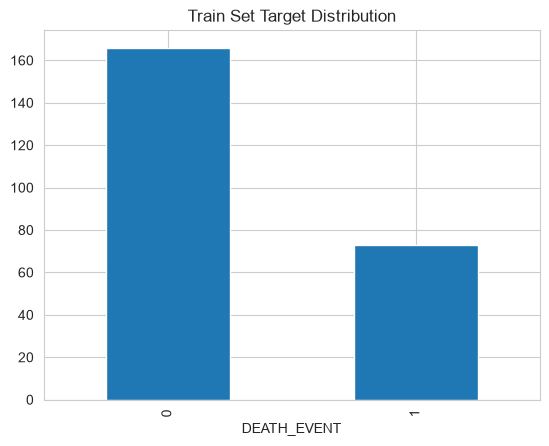

In [ ]:
import matplotlib.pyplot as plt
y_train.value_counts().plot(kind='bar', title='Train Set Target Distribution')
plt.show()

Use SMOTE to balance Train Set target

In [ ]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE(sampling_strategy='minority', random_state=0)
X_train, y_train = oversample.fit_resample(X_train, y_train)
print(X_train.shape, y_train.shape, X_test.shape, y_test.shape)

(332, 11) (332,) (60, 11) (60,)


Check Train Set Target distribution after SMOTE

## Grid Search CV: Sklearn

Using the most suitable model from the last section and its best hyperparameter configuration.

We are using the same model from  the last GridCV search

In [ ]:
models_search   # XGBClassifier

{'XGBClassifier': XGBClassifier(base_score=None, booster=None, callbacks=None,
               colsample_bylevel=None, colsample_bynode=None,
               colsample_bytree=None, device=None, early_stopping_rounds=None,
               enable_categorical=True, eval_metric=None, feature_types=None,
               feature_weights=None, gamma=None, grow_policy=None,
               importance_type=None, interaction_constraints=None,
               learning_rate=None, max_bin=None, max_cat_threshold=None,
               max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
               max_leaves=None, min_child_weight=None, missing=nan,
               monotone_constraints=None, multi_strategy=None, n_estimators=None,
               n_jobs=None, num_parallel_tree=None, ...)}

And the best parameters from the last GridCV search 

In [ ]:
best_parameters

{'model__learning_rate': 0.01, 'model__max_depth': 3}

You will need to type in manually since the hyperparameter values have to be a list. The previous dictionary is not in this format.

In [ ]:
params_search = {'XGBClassifier':  {
    'model__learning_rate': [0.01],   # the value should be in []
    'model__max_depth': [3]},  # the value should be in []
}
params_search


{'XGBClassifier': {'model__learning_rate': [0.01], 'model__max_depth': [3]}}

GridSearch CV

In [ ]:
from sklearn.metrics import recall_score, make_scorer
quick_search = HyperparameterOptimizationSearch(
    models=models_search, params=params_search)
quick_search.fit(X_train, y_train,
                 scoring=make_scorer(recall_score, pos_label=1),
                 n_jobs=-1, cv=5)



Running GridSearchCV for XGBClassifier 

Fitting 5 folds for each of 1 candidates, totalling 5 fits


Check results

In [ ]:
grid_search_summary, grid_search_pipelines = quick_search.score_summary(sort_by='mean_score')
grid_search_summary 

,estimator,min_score,mean_score,max_score,std_score,model__learning_rate,model__max_depth
0,XGBClassifier,0.676471,0.777718,0.878788,0.064928,0.01,3


Define the best clf pipeline

In [ ]:
best_model = grid_search_summary.iloc[0, 0]
pipeline_clf = grid_search_pipelines[best_model].best_estimator_
pipeline_clf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['ejection_fraction','serum_creatinine','age',...,'anaemia','diabetes', 'platelets']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Assess feature importance

* These are the 11 most important features in descending order. The model was trained on them: 
['serum_creatinine', 'ejection_fraction', 'age', 'sex', 'creatinine_phosphokinase', 'platelets', 'serum_sodium', 'diabetes', 'smoking', 'anaemia', 'high_blood_pressure']


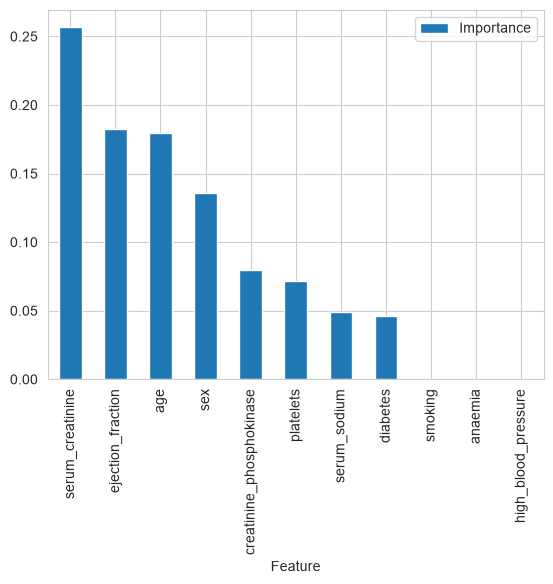

In [ ]:
best_features = X_train.columns

# create DataFrame to display feature importance
df_feature_importance = (pd.DataFrame(data={
    'Feature': best_features,
    'Importance': pipeline_clf['model'].feature_importances_})
    .sort_values(by='Importance', ascending=False)
)


# Most important features statement and plot
print(f"* These are the {len(best_features)} most important features in descending order. "
      f"The model was trained on them: \n{df_feature_importance['Feature'].to_list()}")

df_feature_importance.plot(kind='bar', x='Feature', y='Importance')
plt.show()


In [ ]:
clf_performance(X_train=X_train, y_train=y_train,
                X_test=X_test, y_test=y_test,
                pipeline=pipeline_clf,
                label_map= ['No Churn', 'Churn'] 
                )

#### Train Set #### 

---  Confusion Matrix  ---
                    Actual No Churn Actual Churn
Prediction No Churn             137           27
Prediction Churn                 29          139


---  Classification Report  ---
              precision    recall  f1-score   support

    No Churn       0.84      0.83      0.83       166
       Churn       0.83      0.84      0.83       166

    accuracy                           0.83       332
   macro avg       0.83      0.83      0.83       332
weighted avg       0.83      0.83      0.83       332
 

#### Test Set ####

---  Confusion Matrix  ---
                    Actual No Churn Actual Churn
Prediction No Churn              32            8
Prediction Churn                  5           15


---  Classification Report  ---
              precision    recall  f1-score   support

    No Churn       0.80      0.86      0.83        37
       Churn       0.75      0.65      0.70        23

    accuracy                           0.78      

# Step 4: Push files to Repo

We will generate the following files
* Train set
* Test set
* Data cleaning and Feature Engineering pipeline
* Modeling pipeline
* features importance plot

In [ ]:
import joblib
import os

version = 'v1'
file_path = f'outputs/ml_pipeline/predict_death_event/{version}'

try:
    os.makedirs(name=file_path)
except Exception as e:
    print(e)

## Train Set

* note that the variables **are transformed already** in X_train and the shape is 8266 - after SMOTE was applied.

In [ ]:
print(X_train.shape)
X_train.head()

(332, 11)


,ejection_fraction,serum_creatinine,age,sex,serum_sodium,smoking,creatinine_phosphokinase,high_blood_pressure,anaemia,diabetes,platelets
0,35,1.18,81.0,1,137,1,4540,0,0,0,231000.0
1,30,0.70,50.0,1,141,1,185,0,0,0,266000.0
2,35,1.00,45.0,1,145,0,582,0,0,0,385000.0
3,38,1.00,52.0,1,140,1,190,0,0,1,382000.0
4,40,0.80,50.0,1,141,0,54,0,1,0,279000.0


In [ ]:
X_train.to_csv(f"{file_path}/X_train.csv", index=False)

In [ ]:
y_train

0      0
1      0
2      1
3      0
4      0
      ..
327    1
328    1
329    1
330    1
331    1
Name: DEATH_EVENT, Length: 332, dtype: int64

In [ ]:
y_train.to_csv(f"{file_path}/y_train.csv", index=False)

## Test Set

* note that the variables are transformed already in X_test

In [ ]:
print(X_test.shape)
X_test.head()

(60, 11)


,ejection_fraction,serum_creatinine,age,sex,serum_sodium,smoking,creatinine_phosphokinase,high_blood_pressure,anaemia,diabetes,platelets
206,40,0.8,40.000,0,141,0,101,0,1,0,226000.0
188,40,1.0,60.667,0,136,0,151,1,1,1,201000.0
12,30,1.1,45.000,1,137,0,981,0,1,0,136000.0
219,35,0.7,55.000,0,140,0,582,1,0,1,371000.0
237,30,1.2,70.000,1,132,0,232,0,0,0,173000.0


In [ ]:
X_test.to_csv(f"{file_path}/X_test.csv", index=False)

In [ ]:
y_test

206    0
188    0
12     1
219    0
237    0
136    0
228    0
205    0
52     1
108    0
240    0
15     1
184    1
246    1
22     1
74     1
269    0
90     0
227    0
255    0
190    0
103    0
124    1
129    0
220    1
116    0
194    1
285    0
294    0
249    0
92     0
66     1
8      1
122    0
217    1
150    1
176    0
182    1
298    0
5      1
263    0
89     0
81     0
34     1
55     1
139    0
234    0
64     0
7      1
45     1
73     0
291    0
173    0
106    0
59     1
230    1
168    0
26     1
283    0
153    0
Name: DEATH_EVENT, dtype: int64

In [ ]:
y_test.to_csv(f"{file_path}/y_test.csv", index=False)

We will save 2 pipelines: 
* Both should be used in conjunction to predict Live Data.
* To predict on Train Set, Test Set we use only pipeline_clf, since the data is already processed.



Pipeline responsible for Data Cleaning and Feature Engineering.


In [ ]:
pipeline_data_cleaning_feat_eng

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('OrdinalCategoricalEncoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,encoding_method,'arbitrary'
,variables,"['InternetService', 'Contract']"
,missing_values,'raise'
,ignore_format,False
,unseen,'ignore'


In [ ]:
%pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [ ]:

import joblib
from pathlib import Path

# Define project directory
PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

# Define folder for saving pipelines
file_path = PROJECT_ROOT / "outputs" / "models"

# Create folder if it doesn't exist
file_path.mkdir(parents=True, exist_ok=True)

# Save fitted preprocessing pipeline
joblib.dump(
    value=pipeline_data_cleaning_feat_eng,
    filename=file_path / "clf_pipeline_data_cleaning_feat_eng.pkl"
)

print("Pipeline saved successfully!")


Pipeline saved successfully!


In [ ]:
import joblib
joblib.dump(value=pipeline_data_cleaning_feat_eng ,
            filename=f"{file_path}/clf_pipeline_data_cleaning_feat_eng.pkl")

['C:\\python_projects\\Predictive_analysis\\outputs\\models/clf_pipeline_data_cleaning_feat_eng.pkl']

* Pipeline responsible for Feature Scaling, and Model

In [ ]:
pipeline_clf

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['ejection_fraction','serum_creatinine','age',...,'anaemia','diabetes', 'platelets']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [ ]:
joblib.dump(value=pipeline_clf ,
            filename=f"{file_path}/clf_pipeline_model.pkl")

['C:\\python_projects\\Predictive_analysis\\outputs\\models/clf_pipeline_model.pkl']

## Feature Importance plot

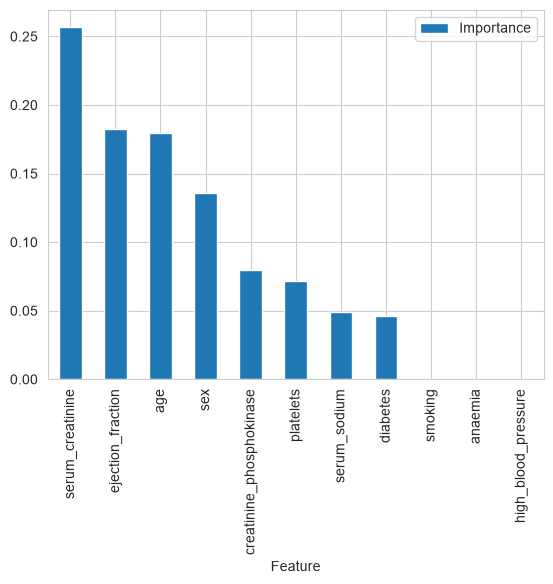

In [ ]:
df_feature_importance.plot(kind='bar',x='Feature',y='Importance')
plt.show()

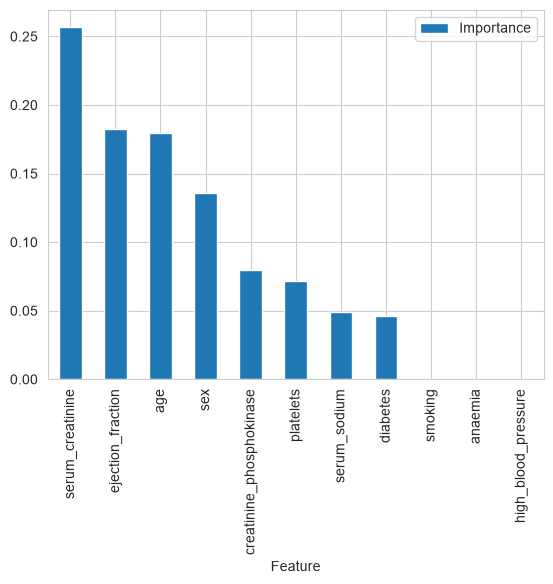

In [ ]:
df_feature_importance.plot(kind='bar', x='Feature', y='Importance')
plt.savefig(f'{file_path}/features_importance.png', bbox_inches='tight')

Good job, you should clear outputs, then run git commands to push files to the repo. Next, move on to Predict Tenure notebook

In [ ]:

import numpy as np
import pandas as pd
import joblib

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# ---------------------------------------
# 1. Define project paths
# ---------------------------------------

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

DATA_DIR = PROJECT_ROOT / "outputs" / "datasets" / "split"

SAVE_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "ml_pipeline"
    / "predict_death_event"
    / "v1"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------
# 2. Load training and test datasets
# ---------------------------------------

TrainSet = pd.read_csv(DATA_DIR / "TrainSet.csv")
TestSet = pd.read_csv(DATA_DIR / "TestSet.csv")

X_train = TrainSet.drop(columns=["DEATH_EVENT", "time"], errors="ignore")
y_train = TrainSet["DEATH_EVENT"]

X_test = TestSet.drop(columns=["DEATH_EVENT", "time"], errors="ignore")
y_test = TestSet["DEATH_EVENT"]

# ---------------------------------------
# 3. Define feature groups
# ---------------------------------------

log_features = ["creatinine_phosphokinase"]

numerical_features = [
    "age",
    "ejection_fraction",
    "platelets",
    "serum_creatinine",
    "serum_sodium"
]

binary_features = [
    "anaemia",
    "diabetes",
    "high_blood_pressure",
    "sex",
    "smoking"
]

# ---------------------------------------
# 4. Create preprocessing pipeline
# ---------------------------------------

log_pipeline = Pipeline([
    ("log_transform", FunctionTransformer(
        np.log1p,
        feature_names_out="one-to-one"
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("log", log_pipeline, log_features),
        ("num", StandardScaler(), numerical_features),
        ("binary", "passthrough", binary_features)
    ],
    verbose_feature_names_out=False
)

# ---------------------------------------
# 5. Transform training and test data
# ---------------------------------------

X_train_transformed = preprocessor.fit_transform(X_train)
X_test_transformed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_fe = pd.DataFrame(
    X_train_transformed,
    columns=feature_names,
    index=X_train.index
)

X_test_fe = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print("Training shape:", X_train_fe.shape)
print("Test shape:", X_test_fe.shape)

# ---------------------------------------
# 6. Train Logistic Regression
# ---------------------------------------

clf_pipeline_model = LogisticRegression(
    max_iter=2000,
    random_state=42,
    class_weight="balanced"
)

clf_pipeline_model.fit(X_train_fe, y_train)

# ---------------------------------------
# 7. Evaluate classifier
# ---------------------------------------

y_pred = clf_pipeline_model.predict(X_test_fe)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# ---------------------------------------
# 8. Save fitted pipelines
# ---------------------------------------

joblib.dump(
    preprocessor,
    SAVE_DIR / "clf_pipeline_data_cleaning_feat_eng.pkl"
)

joblib.dump(
    clf_pipeline_model,
    SAVE_DIR / "clf_pipeline_model.pkl"
)

# ---------------------------------------
# 9. Save transformed datasets
# ---------------------------------------

X_train_fe.to_csv(SAVE_DIR / "X_train.csv", index=False)
X_test_fe.to_csv(SAVE_DIR / "X_test.csv", index=False)

y_train.to_csv(SAVE_DIR / "y_train.csv", index=False)
y_test.to_csv(SAVE_DIR / "y_test.csv", index=False)

print("\nFiles saved successfully:")
for file in SAVE_DIR.iterdir():
    print(file.name)


Training shape: (239, 11)
Test shape: (60, 11)

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.78      0.80        41
           1       0.57      0.63      0.60        19

    accuracy                           0.73        60
   macro avg       0.70      0.71      0.70        60
weighted avg       0.74      0.73      0.74        60


Confusion Matrix:
[[32  9]
 [ 7 12]]

Files saved successfully:
clf_pipeline_data_cleaning_feat_eng.pkl
clf_pipeline_model.pkl
X_test.csv
X_train.csv
y_test.csv
y_train.csv


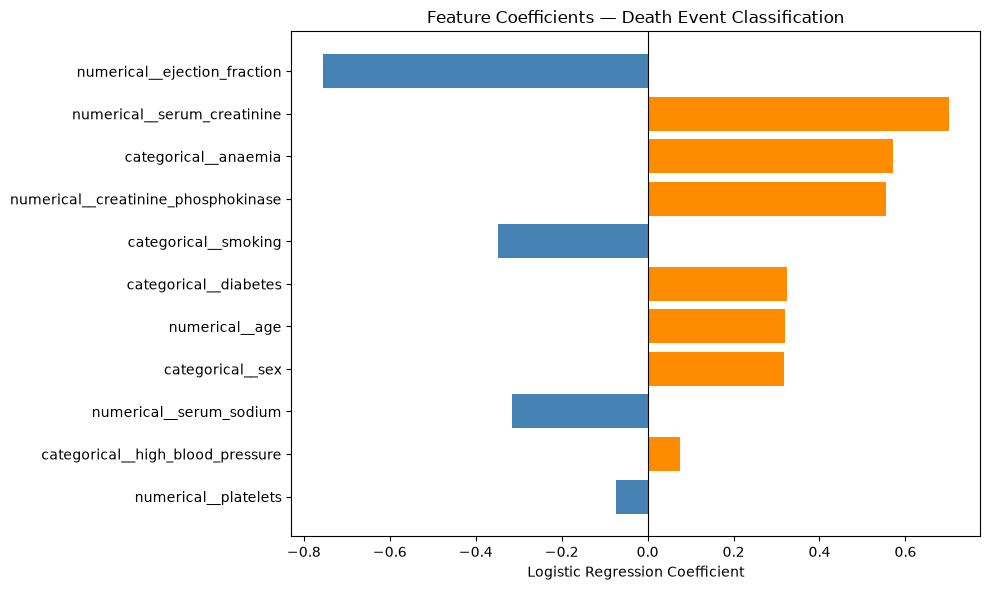

Image saved: C:\python_projects\Predictive_analysis\outputs\ml_pipeline\predict_death_event\v1\features_importance.png
File exists: True


In [17]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from pathlib import Path

PROJECT_ROOT = Path(r"C:\python_projects\Predictive_analysis")

MODEL_DIR = (
    PROJECT_ROOT
    / "outputs"
    / "ml_pipeline"
    / "predict_death_event"
    / "v1"
)

# Load the saved model and preprocessor
model = joblib.load(MODEL_DIR / "clf_pipeline_model.pkl")
preprocessor = joblib.load(
    MODEL_DIR / "clf_pipeline_data_cleaning_feat_eng.pkl"
)

# Get the feature names in model input order
feature_names = preprocessor.get_feature_names_out()

# Extract logistic regression coefficients
coefficients = model.coef_[0]

if len(feature_names) != len(coefficients):
    raise ValueError("Feature names and model coefficients do not match.")

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Coefficient": np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by="Absolute_Coefficient",
    ascending=True
)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))

colors = [
    "steelblue" if coef < 0 else "darkorange"
    for coef in feature_importance["Coefficient"]
]

ax.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"],
    color=colors
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_xlabel("Logistic Regression Coefficient")
ax.set_title("Feature Coefficients — Death Event Classification")

plt.tight_layout()

# Save image
image_path = MODEL_DIR / "features_importance.png"

fig.savefig(image_path, dpi=300, bbox_inches="tight")

plt.show()

print("Image saved:", image_path)
print("File exists:", image_path.exists())


In [18]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

y_prob = clf_pipeline_model.predict_proba(X_test_fe)[:, 1]

results = []

for threshold in np.arange(0.20, 0.81, 0.05):
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Death Recall": recall_score(y_test, y_pred),
        "Death Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Death F1": f1_score(y_test, y_pred)
    })

threshold_results = pd.DataFrame(results)

display(threshold_results)

NameError: name 'X_test_fe' is not defined

---

In [1]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_val_score(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print(f"Mean ROC-AUC: {scores.mean():.4f}")
print(f"Standard deviation: {scores.std():.4f}")

NameError: name 'preprocessor' is not defined